# Run SCENIC to annotate novel cell subclusters

**Author:** Wei Yang

### Dataset Summary
* **Input:** Filtered `.h5ad` file from preprocessing organized by inidividual cell type
* **Output:** TF regulon enrichment scores for each cell subluster within individual cell type

In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import loompy as lp
import re
import random
import anndata as ad
import time
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import platform
import subprocess

/home/wyang114/.conda/envs/pyscenic/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/home/wyang114/.conda/envs/pyscenic/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/home/wyang114/.conda/envs/pyscenic/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/home/wyang114/.conda/envs/pyscenic/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/home/wyang114/.conda/envs/pyscenic/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: 

In [5]:
#open anndata 
processed_dir = '/scratch/nsnyderm/u01/intermediate_files/cell-class_h5ad_update/'
files = os.listdir(processed_dir)
files = [file for file in files if re.search(r'Res1',file)]
file = 'Res1_glutamatergic-neurons_update.h5ad'
selected_lv = [str(i) for i in [5,0,17,27,29,16,24,30,28]]
ct = file.split('_',3)[1]+'_L2-3_TEST'

In [6]:
#working directory
wdir = f"/scratch/wyang114/bin/GRN/{ct}"
os.makedirs(wdir,exist_ok=True)
os.chdir(wdir)
#loom file (after filtering)
f_loom_path_scenic = ct+"_filtered_scenic.loom"
#path to anndata object generated
f_anndata_path = processed_dir+file
#path to pyscenic output
f_pyscenic_output = f'{ct}_pyscenic_output.h5ad'

In [7]:
#set params
"""
changed packages:
numpy=2.0.2 --> 1.23.5
dask-expr=1.1.20 --> 0.5.3 
distributed=2024.12.0 --> 2024.2.1
scipy=1.14.1 --> 1.13.1
"""
sc.settings.verbosity = 3 # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.logging.print_versions()
sc.set_figure_params(dpi=150, fontsize=10, dpi_save=600)
sc.settings.njobs = 20

-----
anndata     0.11.1
scanpy      1.10.3
-----
PIL                 11.0.0
asttokens           NA
cloudpickle         3.1.0
colorama            0.4.6
comm                0.2.2
cycler              0.12.1
cython_runtime      NA
cytoolz             1.0.1
dask                2024.2.1
dateutil            2.9.0.post0
debugpy             1.8.11
decorator           5.1.1
exceptiongroup      1.2.2
executing           2.1.0
h5py                3.12.1
ipykernel           6.29.5
jedi                0.19.2
jinja2              3.1.4
joblib              1.4.2
kiwisolver          1.4.7
legacy_api_wrap     NA
llvmlite            0.43.0
loompy              3.0.7
lz4                 4.3.3
markupsafe          3.0.2
matplotlib          3.9.4
mpl_toolkits        NA
natsort             8.4.0
numba               0.60.0
numexpr             2.10.2
numpy               1.23.5
numpy_groupies      0.11.2
packaging           24.2
pandas              2.2.3
parso               0.8.4
patsy               1.0.1
platfor

/home/wyang114/.conda/envs/pyscenic/lib/python3.10/site-packages/session_info/main.py:213: UserWarning: The '__version__' attribute is deprecated and will be removed in MarkupSafe 3.1. Use feature detection, or `importlib.metadata.version("markupsafe")`, instead.
  mod_version = _find_version(mod.__version__)


In [8]:
# Reading in adata and convert to loom
# Make sure the data are filtered:min_genes, min_cells, n_genes , percent_mito
# select vars with gene_short_name with 1-to-1 human orthologs
# merge duplicated gene_short_name by summing their counts
# lift-over to human orthologs
adata = sc.read_h5ad(f_anndata_path) 
selected_ids = adata.obs_names[np.where(adata.obs['louvain'].isin(selected_lv))] 
adata = adata[selected_ids,:]
print(adata.shape)

mart = pd.read_csv('/scratch/wyang114/bin/liftover/ensembl113_mmul10_macaque_human.csv')
print(mart.shape)
#select one-to-one orthologs
mart_filtered = mart.loc[mart['Human homology type']=='ortholog_one2one',]
print(mart_filtered.shape)
#remove NAs in macaque and human gene name
mart_dropna = mart_filtered.dropna(subset=['Gene name','Human gene name'])
print(mart_dropna.shape)
#filter to gene name in adata
mart_adata = mart_dropna.loc[mart_dropna['Gene name'].isin(adata.var['external_gene_name']),]
print(mart_adata.shape)
# # #For macaque genes with multiple paralogs or pseudogenes in human, these are not well annotated in macaque 
# # #(remove  it for now: 39 of them, including snRNAs (U1-U12), snoRNAs (SNORD, SNORA), rRNA (5S_rRNA), 
# # #ribonuceoprotein (SRP RNA, Vault RNA)
# # duplicates = mart_adata.loc[mart_adata.duplicated(subset=['Gene name']),'Gene name'].unique()
# # mart_adata = mart_adata.loc[~mart_adata['Gene name'].isin(duplicates),:]
# # print(mart_adata.shape)

(36881, 8)
(19955, 8)
(19531, 8)
(18408, 8)


In [ ]:
#convert to hgnc gene name
#prepare macaque matrix, var: sum counts mapping to the same gene name
cell_filter = 100 #filter out genes expressed in <100 cells to accelerate or select TF of interest
adata.var['nCell'] = np.array(np.sum(adata.X>0 , axis=0)).flatten()
adata = adata[:,(adata.var['nCell']>=cell_filter) & (adata.var['ensembl_gene_id'].isin(mart_adata['Gene stable ID']))].copy() 
gene_dict = {key: value for key, value in zip(mart_adata['Gene stable ID'], mart_adata['Human gene name'])}
adata.var['human_gene_name'] = adata.var['ensembl_gene_id'].map(gene_dict)
#If >100k, downsample to 100k
if(adata.shape[0]>100000):
    names = adata.obs_names.tolist().copy()
    random.shuffle(names)
    select_names = names[:100000]
    adata = adata[select_names,:]
print(adata.shape)
X=adata.X
one_hot_sample = pd.get_dummies(adata.var['human_gene_name']).values.astype(int)
pb_sample_mat = X.dot(one_hot_sample)
print(pb_sample_mat.shape)
pb_var = pd.DataFrame(adata.var.groupby(['human_gene_name']).size().rename('n_mm_geneid')).reset_index()
pb_var = pb_var[pb_var['n_mm_geneid']>0]
pb_var.index = pb_var['human_gene_name']
pb_adata = ad.AnnData(pb_sample_mat,obs = adata.obs, var = pb_var)
pb_adata.write_h5ad(f'{ct}_liftover_adata.h5ad')

/tmp/ipykernel_3373898/2431610988.py:4: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var['nCell'] = np.array(np.sum(adata.X>0 , axis=0)).flatten()


(100000, 15417)


In [41]:
#Convert to loom
#500k cells do not fit with 200GB memory?? 100k x 16k works for 200G. 
row_attrs = { 
    "Gene": np.array(pb_adata.var.index) ,
}
col_attrs = { 
    "CellID":  np.array(pb_adata.obs.index) ,
    "nGene": np.array( np.sum(pb_adata.X.transpose()>0 , axis=0)).flatten() ,
    "nUMI": np.array( np.sum(pb_adata.X.transpose() , axis=0)).flatten() ,
}
if os.path.exists(f_loom_path_scenic):
    os.remove(f_loom_path_scenic)
lp.create(f_loom_path_scenic, pb_adata.X.transpose(), row_attrs, col_attrs)

In [42]:
f_tfs = "/scratch/wyang114/data/cisTarget_databases/tf_lists/allTFs_hg38.txt" #human
with open(f_tfs, "r") as file:
    tfs = [line.strip() for line in file] 

In [43]:
len(tfs)

1892

In [44]:
sum(pb_adata.var.index.isin(tfs)) #1593 with no cell filter

1395

In [45]:
pb_adata.shape

(100000, 15475)

### SCENIC

In [ ]:
"""
STEP1: generate co-expression modules (12693 x 9477: 222s)
input: count matrix from scenic_loom
output: list of adjacencies between a TF and its targets stored
"""
# transcription factors list with gene short name(https://resources.aertslab.org/cistarget/tf_lists/)
f_tfs = "/scratch/wyang114/data/cisTarget_databases/tf_lists/allTFs_hg38.txt" # human
##run scenic to generate adj matrix
start =time.time()
!module load mamba/latest
!source activate pyscenic && pyscenic grn {f_loom_path_scenic} {f_tfs} -o adj.csv --num_workers 20 --sparse --gene_attribute Gene --cell_id_attribute CellID --method grnboost2
end = time.time()
print(end-start)
adjacencies = pd.read_csv("adj.csv", index_col=False, sep=',')
adjacencies.head()


This module is intended solely for building or source activating user
python environments, i.e.,

    mamba create -n myenv -c conda-forge

or

    source activate myenv

To list available environments, run:

    mamba info --envs

See our docs: https://links.asu.edu/solpy

Any other use is NOT TESTED.

  

2024-12-28 20:59:19,802 - pyscenic.cli.pyscenic - INFO - Loading expression matrix.

2024-12-28 21:00:17,176 - pyscenic.cli.pyscenic - INFO - tf_names:1892,ZNF354C

2024-12-28 21:00:17,180 - pyscenic.cli.pyscenic - INFO - match between gene and tf_names:1395,5_8S_rRNA,A1BG

2024-12-28 21:00:17,180 - pyscenic.cli.pyscenic - INFO - Inferring regulatory networks.
preparing dask client
parsing input
creating dask graph
20 partitions
computing dask graph
/home/wyang114/.conda/envs/pyscenic/lib/python3.10/site-packages/distributed/client.py:3169: UserWarning: Sending large graph of size 2.25 GiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  wa

(array([529., 239.,  91.,  41.,  23.,   7.,  13.,   4.,   5.,   5.]),
 array([  96. ,  695.6, 1295.2, 1894.8, 2494.4, 3094. , 3693.6, 4293.2,
        4892.8, 5492.4, 6092. ]),
 <BarContainer object of 10 artists>)

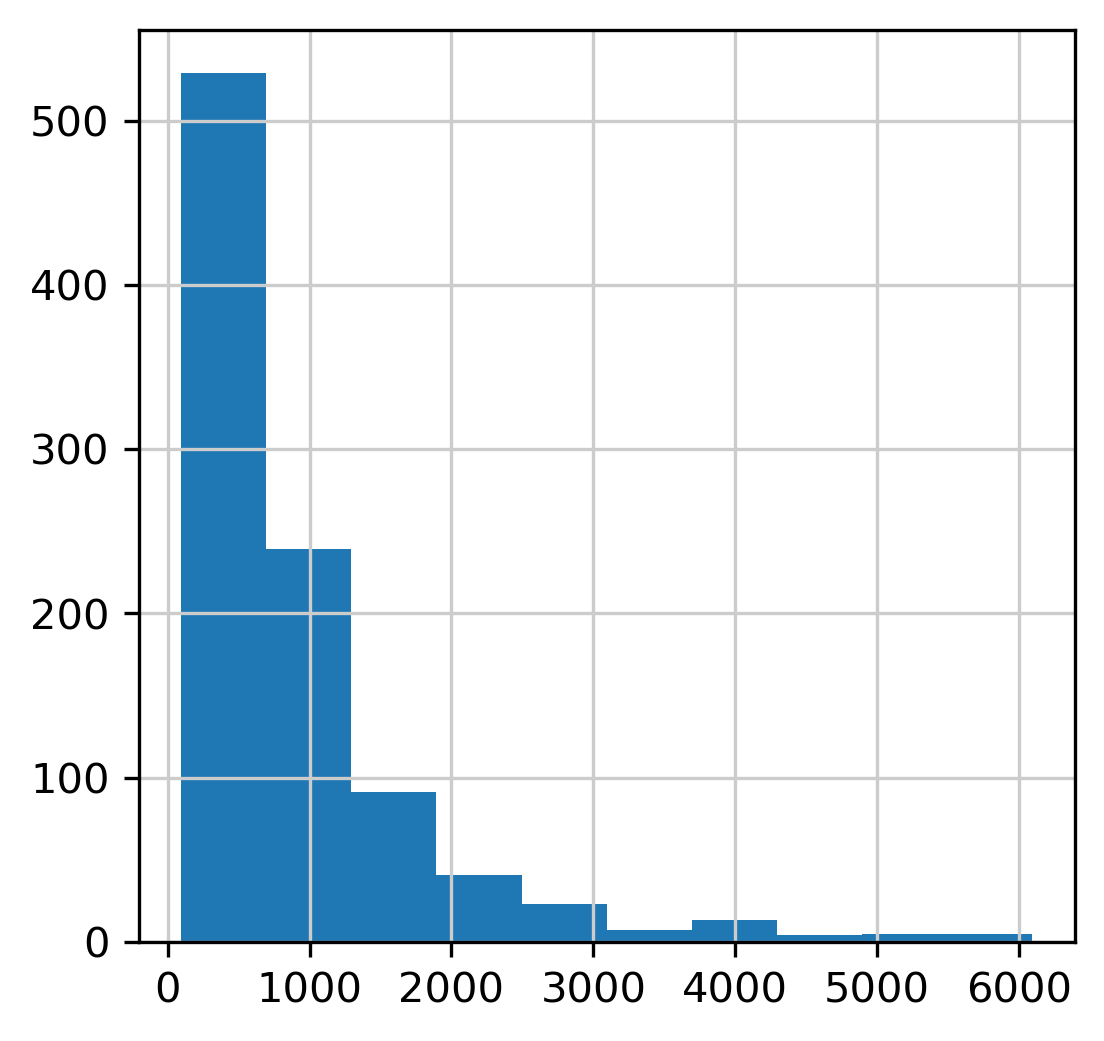

In [40]:
plt.hist(adjacencies['TF'].value_counts())

In [46]:
"""
STEP2-3:Regulon prediction aka cisTarget from CLI (349s)
Input: databases in cisTarget (https://resources.aertslab.org/cistarget/)
Output: List of adjacencies between a TF and its targets stored in MOTIFS_FNAME (reg.csv)
"""
import glob

"""
ranking databases: motif enrichment, gene rankings for potential targets of transcription factors (TFs)
mc_v10_clust (RECOMMENDED): cisTarget databases generated using the 2022 SCENIC+ motif collection.

scores: Matrix containing motifs as rows and genes as columns and cluster-buster CRM scores as values. To be used with DEM. 
motif represented by PWM as likelihood of observing a nucleotide at a given position, Cluster-Buster call regions where motifs 
are closely packed and score the region based on PWM score, motif distance and occurances

rankings: Matrix containing motifs as rows and genes as columns and ranking position for each gene and motif (based on CRM scores)
as values. To be used with cisTarget (R).

"""
f_db_glob = "/scratch/wyang114/data/cisTarget_databases/mc9nr_ranking/human/*feather"
f_db_names = ' '.join( glob.glob(f_db_glob) )

"""
# motif databases: motif annotation (JASPAR, TRANSFAC, or ENCODE)
"""
f_motif_path = "/scratch/wyang114/data/cisTarget_databases/motif2tf/motifs-v10nr_clust-nr.hgnc-m0.001-o0.0.tbl"

#Run scenic:mask_dropout(mask out cells with 0 counts of TF or target genes)
start =time.time()
!source activate pyscenic && pyscenic ctx adj.csv \
    {f_db_names} \
    --annotations_fname {f_motif_path} \
    --expression_mtx_fname {f_loom_path_scenic} \
    --output reg.csv \
    --mask_dropouts \
    --num_workers 20
end = time.time()
print(f'{end-start}s')


2024-12-14 22:05:28,016 - pyscenic.cli.pyscenic - INFO - Creating modules.

2024-12-14 22:05:28,350 - pyscenic.cli.pyscenic - INFO - Loading expression matrix.

2024-12-14 22:05:42,712 - pyscenic.utils - INFO - Calculating Pearson correlations.

2024-12-14 22:05:42,820 - pyscenic.utils - WARNING - Note on correlation calculation: the default behaviour for calculating the correlations has changed after pySCENIC verion 0.9.16. Previously, the default was to calculate the correlation between a TF and target gene using only cells with non-zero expression values (mask_dropouts=True). The current default is now to use all cells to match the behavior of the R verision of SCENIC. The original settings can be retained by setting 'rho_mask_dropouts=True' in the modules_from_adjacencies function, or '--mask_dropouts' from the CLI.
	Dropout masking is currently set to [True].

2024-12-14 22:05:48,973 - pyscenic.utils - INFO - Creating modules.

2024-12-14 22:06:13,677 - pyscenic.cli.pyscenic - IN

In [75]:
reg = pd.read_csv("reg.csv", index_col=False, sep=',',skiprows=1)
reg = reg[1:]
reg.rename(columns={reg.columns[0]: 'TF', reg.columns[1]: 'MotifID'}, inplace=True)

In [77]:
reg['TF'].value_counts()

TF
ETV1       50
KLF12      49
FLI1       42
STAT1      41
SREBF2     38
           ..
FOXP1       1
FOXN2       1
ZNF382      1
TBR1        1
ZSCAN29     1
Name: count, Length: 236, dtype: int64

In [59]:
reg.columns[2:9]

Index(['AUC', 'NES', 'MotifSimilarityQvalue', 'OrthologousIdentity',
       'Annotation', 'Context', 'TargetGenes'],
      dtype='object')

In [60]:
reg.iloc[1,2:9]=reg.columns[2:9].tolist()

In [61]:
reg.iloc[1,2:9]

AUC                                        AUC
NES                                        NES
MotifSimilarityQvalue    MotifSimilarityQvalue
OrthologousIdentity        OrthologousIdentity
Annotation                          Annotation
Context                                Context
TargetGenes                        TargetGenes
Name: 1, dtype: object

In [21]:
"""
STEP4: Cellular enrichment (AUCell)
Most cells should have a substantial fraction of expressed/detected genes.
--auc_threshold sets threshold on the cells to use.
"""   
#adata = sc.read_h5ad(f'{ct}_liftover_adata.h5ad')
#nGenesDetectedPerCell = np.sum(adata.X>0, axis=1)
##percentiles = nGenesDetectedPerCell.quantile([.01, .05, .10, .50, 1])

# percentiles = np.quantile(nGenesDetectedPerCell, [0.01, 0.05, 0.10, 0.50, 1.0])
# print(percentiles)

# fig, ax = plt.subplots(1, 1, figsize=(8, 5), dpi=150)
# sns.distplot(nGenesDetectedPerCell, norm_hist=False, kde=False, bins='fd')
# quantile_levels = [0.01,0.05,0.1,0.5,1]
# for i,x in enumerate(percentiles):
#     fig.gca().axvline(x=x, ymin=0,ymax=1, color='red')
#     ax.text(x=x, y=ax.get_ylim()[1], s=f'{int(x)} ({quantile_levels[i]*100}%)', color='red', rotation=30, size='x-small',rotation_mode='anchor' )
# ax.set_xlabel('# of genes')
# ax.set_ylabel('# of cells')
# fig.tight_layout()
# fig.savefig("nGenesDetectedPerCell_percentile.png", dpi=150)

#Run aucell
f_loom_path_scenic = f'{ct}_liftover_adata.h5ad'
f_pyscenic_output = f'{ct}_pyscenic_output.h5ad'

start =time.time()
reg_file = f'{ct}_reg.csv'
!source activate pyscenic && pyscenic aucell \
    {f_loom_path_scenic} \
    {reg_file} \
    --output {f_pyscenic_output} \
    --num_workers 20
end = time.time()
print(f'{end-start}s')


2024-12-31 16:40:41,710 - pyscenic.cli.pyscenic - INFO - Loading expression matrix.
glutamatergic-neurons_liftover_adata.h5ad

2024-12-31 16:41:10,677 - pyscenic.cli.pyscenic - INFO - Loading gene signatures.
Create regulons from a dataframe of enriched features.
Additional columns saved: []

2024-12-31 16:41:12,129 - pyscenic.cli.pyscenic - INFO - Calculating cellular enrichment.

2024-12-31 16:43:40,159 - pyscenic.cli.pyscenic - INFO - Writing results to file.
508.98319578170776s


## Read outputs

In [2]:
ct = 'opc-olig_all'
wdir = f"/scratch/wyang114/outputs/regulon/{ct}"
os.chdir(wdir)
adata = sc.read_h5ad(f'{ct}_pyscenic_output.h5ad')
# Group by 'Group' and calculate the mean of variables
df = adata.obs.copy()
df_select = df.loc[:, df.columns.str.contains(r'^louvain$|age$|Regulon', case=False, regex=True)]
mean_df = df_select.groupby("louvain").mean()
# Transpose to get the desired format
result = mean_df.transpose()

/tmp/ipykernel_3394776/1700808539.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_df = df_select.groupby("louvain").mean()


# correlation

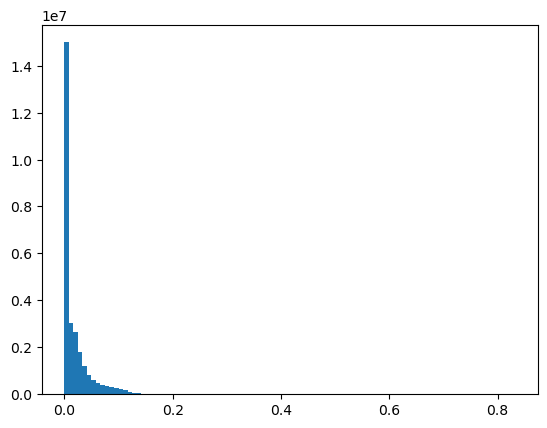

In [19]:
#pooled_values = df_select.iloc[:,2:320].values.flatten()
plt.hist(pooled_values, bins=100);

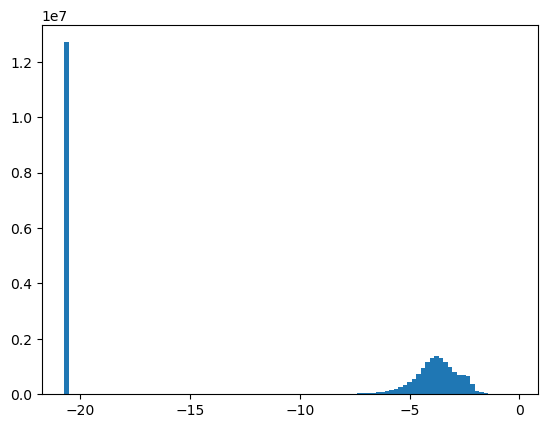

In [24]:
plt.hist(np.log(pooled_values+10e-10), bins=100);

In [20]:
from scipy.stats import spearmanr
# Separate age
age = df_select['age']

# Drop 'age' column to keep only regulon data
regulon_df = df_select.drop(columns=['age','louvain'])

# Compute correlation and p-values for each regulon
corrs = {}
pvals = {}

for regulon in regulon_df.columns:
    corr, pval = spearmanr(regulon_df[regulon], age)  # or pearsonr()
    corrs[regulon] = corr
    pvals[regulon] = pval

# Create result DataFrame
correlation_df = pd.DataFrame({
    'regulon': list(corrs.keys()),
    'correlation': list(corrs.values()),
    'p_value': list(pvals.values())
})

# Optional: sort by correlation strength
correlation_df = correlation_df.sort_values('correlation', ascending=False)

print(correlation_df.tail())

                regulon  correlation        p_value
51     Regulon(ETV1(+))    -0.107639  2.070379e-255
191    Regulon(SOX6(+))    -0.109518  2.198050e-264
96    Regulon(KLF12(+))    -0.110277  4.689160e-268
152  Regulon(PDLIM5(+))    -0.126646   0.000000e+00
55     Regulon(ETV6(+))    -0.135982   0.000000e+00


(array([  2.,   5.,   5.,   5.,  18.,  24., 117.,  76.,  40.,   8.]),
 array([-0.13598162, -0.11582477, -0.09566792, -0.07551107, -0.05535422,
        -0.03519736, -0.01504051,  0.00511634,  0.02527319,  0.04543004,
         0.06558689]),
 <BarContainer object of 10 artists>)

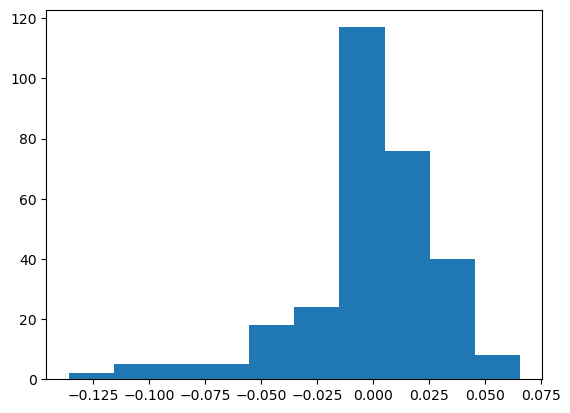

In [21]:
plt.hist(correlation_df['correlation'])

In [22]:
correlation_df.to_csv(f'/scratch/wyang114/bin/GRN/{ct}/regulon_correlation.csv')

In [47]:
from pygam import LinearGAM, s
from sklearn.metrics import r2_score
import pandas as pd

# Assume df has 'age' column and the rest are regulons
regulon_cols = [col for col in df_select.columns if col != 'age']

results = []

for regulon in regulon_cols:
    X = df_select[[regulon]].values  # predictor must be 2D
    y = df_select['age'].values      # target

    try:
        gam = LinearGAM(s(0)).fit(X, y)
        y_pred = gam.predict(X)
        r2 = r2_score(y, y_pred)
        results.append({'regulon': regulon, 'r2': r2})
    except Exception as e:
        print(f"Error with {regulon}: {e}")
        results.append({'regulon': regulon, 'r2': None})

# Convert to DataFrame and sort
results_df = pd.DataFrame(results).sort_values('r2', ascending=False)
results_df = results_df[results_df['regulon'] != 'louvain'].reset_index(drop=True)

# View top correlated regulons
print(results_df.head())

                regulon        r2
0               louvain  0.031208
56     Regulon(ETV6(+))  0.026487
153  Regulon(PDLIM5(+))  0.020967
97    Regulon(KLF12(+))  0.015438
243    Regulon(ZEB1(+))  0.015180


(array([258.,  19.,  11.,   4.,   7.,   0.,   1.,   0.,   1.,   1.]),
 array([5.43894968e-05, 3.16976240e-03, 6.28513530e-03, 9.40050821e-03,
        1.25158811e-02, 1.56312540e-02, 1.87466269e-02, 2.18619998e-02,
        2.49773727e-02, 2.80927456e-02, 3.12081185e-02]),
 <BarContainer object of 10 artists>)

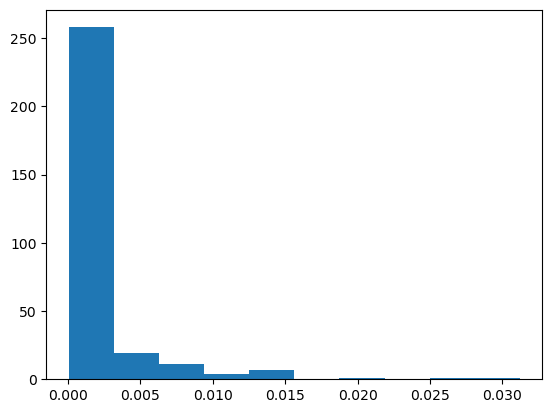

In [34]:
plt.hist(results_df['r2'])

In [51]:
# Define your top regulons to include (e.g., top 5 by R²)
top_regulons = results_df['regulon'].dropna().head(5).tolist()

# Subset data
X = df_select[top_regulons].values  # 2D array of features
y = df['age'].values

# Build a GAM with one smoother per regulon
gam = LinearGAM(s(0) + s(1) + s(2) + s(3) + s(4)).fit(X, y)

# Predict and evaluate
y_pred = gam.predict(X)
r2 = r2_score(y, y_pred)
print(f"Multi-regulon model R²: {r2:.3f}")

Multi-regulon model R²: 0.038


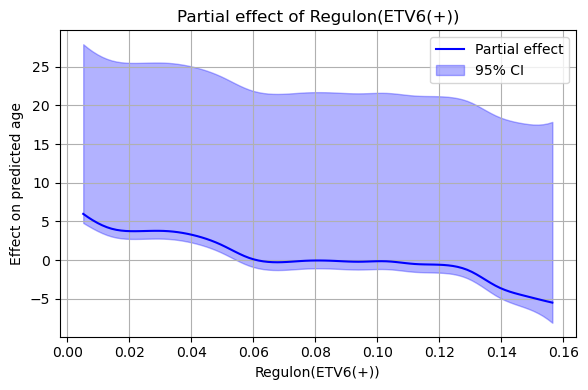

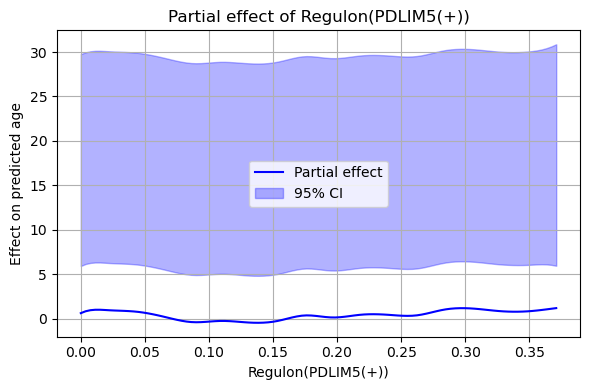

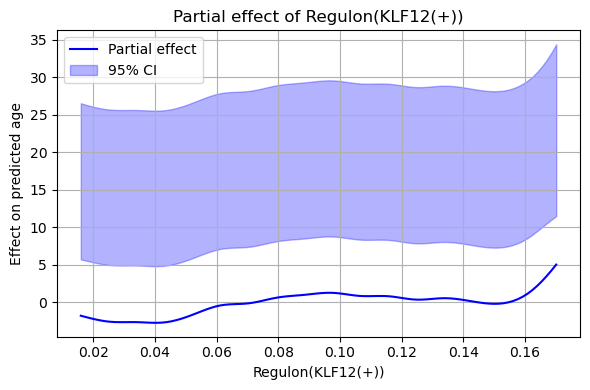

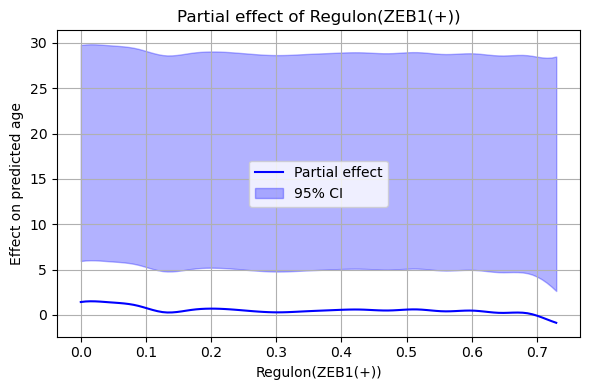

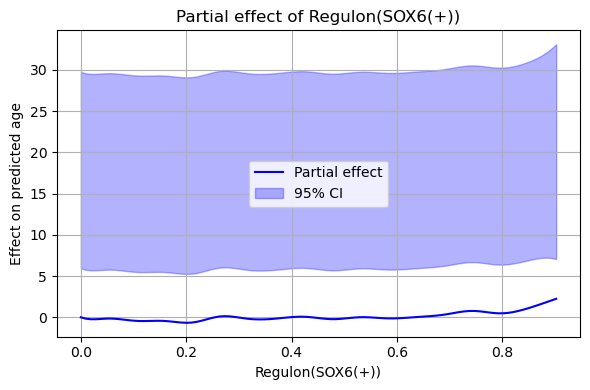

In [52]:
import numpy as np
import matplotlib.pyplot as plt

for i, reg in enumerate(top_regulons):
    # Generate X grid for the i-th term
    XX = gam.generate_X_grid(term=i)

    # Get partial dependence and confidence intervals (built-in method)
    pdep = gam.partial_dependence(term=i, X=XX)
    conf = gam.prediction_intervals(X=XX, width=0.95)

    # Plot only the term's axis (XX[:, i])
    plt.figure(figsize=(6, 4))
    plt.plot(XX[:, i], pdep, label='Partial effect', color='blue')
    plt.fill_between(XX[:, i], conf[:, 0], conf[:, 1], color='blue', alpha=0.3, label='95% CI')
    plt.title(f"Partial effect of {reg}")
    plt.xlabel(reg)
    plt.ylabel("Effect on predicted age")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# subcluster enrichment

(301, 14)


<Axes: xlabel='louvain'>

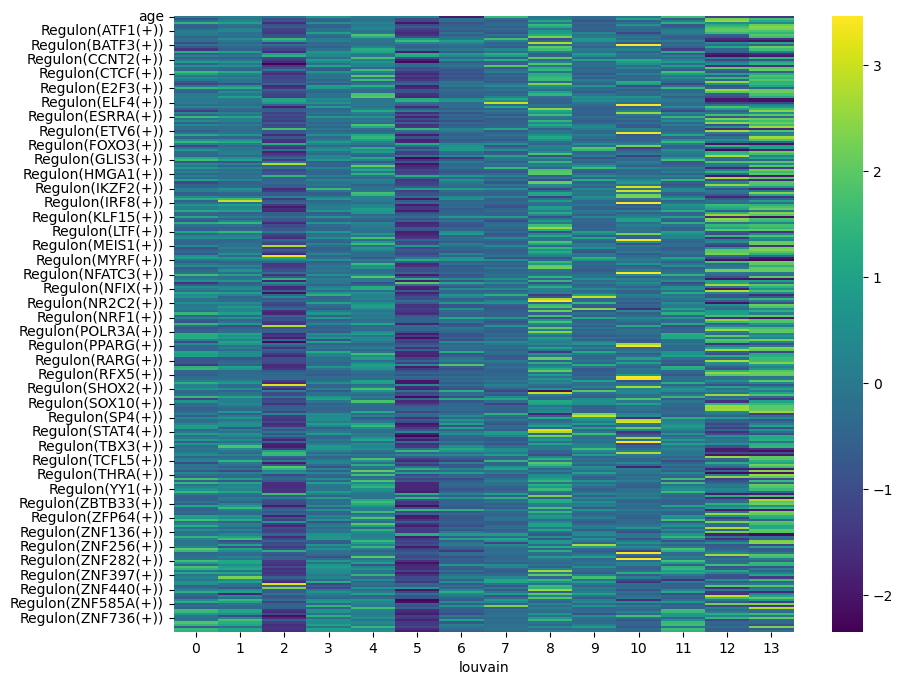

In [3]:
print(result.shape)
plt.figure(figsize=(10,8))
zscore_scaled = result.sub(result.mean(axis=1), axis=0).div(result.std(axis=1), axis=0)
sns.heatmap(zscore_scaled, annot=False, cmap="viridis", cbar=True)

<Axes: xlabel='louvain'>

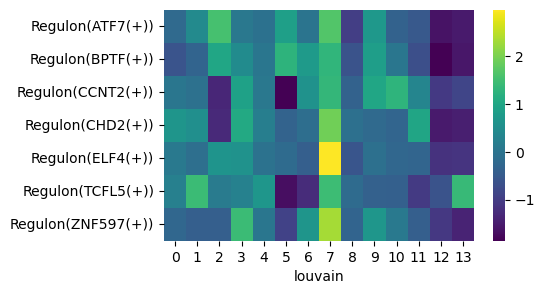

In [4]:
plt.figure(figsize=(5,3))
zscore_scaled = result.sub(result.mean(axis=1), axis=0).div(result.std(axis=1), axis=0)
rows = zscore_scaled.index[zscore_scaled.idxmax(axis=1).isin(['7'])]
sns.heatmap(zscore_scaled.loc[rows,], annot=False, cmap="viridis", cbar=True)

<Axes: xlabel='louvain'>

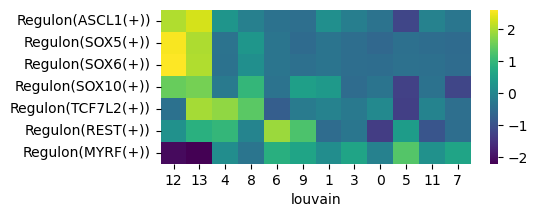

In [92]:
plt.figure(figsize=(5,2))
pattern = re.compile(r"SOX[5|6|10]|TCF7L2|ASCL|MYRF|REST", re.IGNORECASE)
regulons = [item for item in result.index if pattern.search(item)]
sns.heatmap(zscore_scaled.loc[[regulons[i] for i in [0,4,5,3,6,2,1]],
            ['12','13','4','8','6','9','1','3','0','5','11','7']], annot=False, cmap="viridis", cbar=True)